In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Books vs laptops — the laptop figures, redrawn for both domains (2026-11-01)

The figures of [figs4nir.ipynb](figs4nir.ipynb) / [figs4nir2.ipynb](figs4nir2.ipynb), drawn for the laptops and
the books side by side, so the two domains can be compared on the same axes.

**Like with like:**
- **The same 4 instruct models** in both: qwen-32B, qwen-72B, gemma-27B, olmo-32B.
- **Only one-requirement contracts.** Laptops: `14-inch`, `8GB` (frame `shopping`). Books: `fantasy`,
  `mystery-thriller`, `romance`, `classics` (frame `reading`). The two-requirement laptop contract is left out:
  books have no such run.
- **Rank = position-corrected Borda** in both (mean D against all other items; 1 = most preferred). The laptop
  notebooks rank by `FeatureBT` utility; for the laptops the two agree almost perfectly (R² ≥ 0.97, section 3), for
  books they do not, so Borda is the fair common ground.
- **PMI.** The laptop runs of qwen and gemma were collected with PMI on: every stored margin is shifted by one
  constant C per run. D, Borda and the weights do not care. γ and "saturated" do, so C is recovered per run
  (as in figs4nir) and added back. Books and OLMo: PMI off, C = 0.

| here | laptop figure it copies | what it shows |
|---|---|---|
| G1, G1g | F1, F2 | rank of every item, no contract → contract |
| G2 | F5 / F5g | feature weights, with the spread over the 5 templates |
| G3 | F7 / F8 | theoretical (additive) vs empirical utility |
| G4 | F12, figs4nir2 C | the summary: positional bias, sharpness, agreement, ... per domain |
| G5 | F11 | the contract: obeyed? and is the old order kept? |

Book details (features, prompt, contract sentences): [books_48.ipynb](books_48.ipynb), section 0.

In [2]:
import json, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.bt import FeatureBT
import src.alternatives as alt

MODELS = ["qwen-32B", "qwen-72B", "gemma-27B", "olmo-32B"]
DOMS = ["laptops", "books"]
BASES = {"laptops": ["data/laptops_robustness", "data/laptops_robustness_gemma", "data/laptops_olmo"],
         "books": ["data/books"]}
FRAME = {"laptops": "shopping", "books": "reading"}
EXPECT = {"laptops": 45 * 44 * 5, "books": 48 * 47 * 5}
FEATS = {"laptops": ["brand", "screen", "ram"], "books": alt.book_tags}
# Only single-requirement contracts, so the two domains are compared like with like.
CONS = {"laptops": ["none", "screen=14-inch", "ram=8GB"],
        "books": ["none", "fantasy=yes", "mystery-thriller=yes", "romance=yes", "classics=yes"]}
CLAB = {"none": "none", "screen=14-inch": "14-inch", "ram=8GB": "8GB", "fantasy=yes": "fantasy",
        "mystery-thriller=yes": "mystery", "romance=yes": "romance", "classics=yes": "classics"}
PANELS = [(d, c) for d in DOMS for c in CONS[d][1:]]          # the 6 contracts: 2 laptop, 4 book


def item_key(dom, row, p):
    """item name per row (vectorised): the title, or 'Apple 14in 8GB'."""
    if dom == "books":
        return row[f"{p}title"]
    return row[p + "brand"] + " " + row[p + "screen"].str.replace("-inch", "in") + " " + row[p + "ram"]


def pmi_offset(d, tol=0.01):
    """C for runs collected with normalize_pmi=True (laptops qwen/gemma), from saturation (figs4nir)."""
    return d.score_b.max() - d.score_a.max()


def load(dom):
    R = {}
    for base in BASES[dom]:
        for run in sorted(os.listdir(base)):
            cf, sc = f"{base}/{run}/config.json", f"{base}/{run}/scores.csv"
            if not (os.path.isfile(cf) and os.path.isfile(sc)):      # incomplete run: skip
                continue
            c = json.load(open(cf))
            k = (f"{c['model_family']}-{c['model_size']}B", c["constraints_id"])
            if c["frame"]["name"] != FRAME[dom] or k[0] not in MODELS or k[1] not in CONS[dom]:
                continue
            d = pd.read_csv(sc)
            if len(d) != EXPECT[dom]:
                continue
            assert k not in R, f"two complete runs for {dom} {k}"
            # books and olmo were collected with PMI off; laptops qwen/gemma with PMI on
            C = pmi_offset(d) if dom == "laptops" and c["model_family"] != "olmo" else 0.0
            R[k] = (d, C)
    missing = [(m, c) for m in MODELS for c in CONS[dom] if (m, c) not in R]
    assert not missing, missing
    return R


def analyse(dom, d, C):
    """Everything per run. Dt[t, i, j] = position-corrected margin of i over j in template t."""
    d = d.assign(A=item_key(dom, d, "a_"), B=item_key(dom, d, "b_"))
    items = sorted(set(d.A))
    ix = {x: i for i, x in enumerate(items)}
    T = sorted(d.template_idx.unique()); n = len(items)
    M = np.full((len(T), n, n), np.nan)
    M[[T.index(t) for t in d.template_idx], d.A.map(ix), d.B.map(ix)] = (d.score_a - d.score_b).values
    Dt = (M - M.transpose(0, 2, 1)) / 2
    off = ~np.eye(n, dtype=bool); iu = np.triu_indices(n, 1)
    bt_t = np.array([Dt[t][off].reshape(n, n - 1).mean(1) for t in range(len(T))])     # Borda per template
    borda = pd.Series(bt_t.mean(0), index=items)
    raw = M + C                                                     # true margin, slot 1 - slot 2
    a, b = raw[:, iu[0], iu[1]], raw[:, iu[1], iu[0]]
    rk = np.array([pd.Series(x).rank().values for x in bt_t]); rc = np.corrcoef(rk)
    feat = pd.DataFrame({f: d.groupby("A")[f"a_{f}"].first() for f in FEATS[dom]}).loc[items]
    # additive (feature BT) vs empirical (one utility per item = OLS on all rows, same as Borda here)
    cols = ["score_a", "score_b"] + [f"a_{f}" for f in FEATS[dom]] + [f"b_{f}" for f in FEATS[dom]]
    fbt = FeatureBT(pmi_c=C, r2_warn=None).fit(d[cols])
    th = pd.Series([fbt.utility(feat.loc[x].to_dict()) for x in items], index=items)
    em = borda * (n - 1) / n        # balanced complete design: OLS item utility = Borda x (n-1)/n
    th, em = th - th.mean(), em - em.mean()
    sat = ((d.score_a > d.score_a.max() - 0.1) | (d.score_b > d.score_b.max() - 0.1)).mean()
    return dict(d=d, items=items, feat=feat, Dt=Dt, D=Dt.mean(0), borda=borda, fbt=fbt, th=th, em=em,
                gamma=np.nanmean(M) + C, C=C, sat=sat,
                slot=((a > 0) == (b > 0)).mean(),                  # same slot wins both orders
                tmpl=rc[np.triu_indices(len(T), 1)].mean(),
                sharp=np.tanh(np.abs(Dt[:, iu[0], iu[1]]) / 2).mean(),
                spread=borda.std(), r2u=1 - ((em - th) ** 2).sum() / (em ** 2).sum(),
                medD=np.median(np.abs(Dt.mean(0)[iu])))


def satisfies(r, cid):
    f, lvl = cid.split("=")
    return (r["feat"][f] == lvl).values


RUN = {}
for dom in DOMS:
    for k, (d, C) in load(dom).items():
        RUN[(dom, *k)] = analyse(dom, d, C)
print(len(RUN), "runs:", {dom: sum(k[0] == dom for k in RUN) for dom in DOMS})

FIG = "figs/books_vs_laptops"; os.makedirs(FIG, exist_ok=True)
BLUE, GRAY, LGRAY, INK, INK2, GRID = "#2a78d6", "#a3a29d", "#cfcec9", "#0b0b0b", "#52514e", "#e5e4df"
MC = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])); MK = dict(zip(MODELS, "osD^"))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
                     "axes.titlesize": 10.5, "figure.facecolor": "white"})

32 runs: {'laptops': 12, 'books': 20}


## G1 — rank of every item, no contract → contract (laptop F1 / F2)

Each line is one item. **Blue = the item meets the contract**, gray = it does not. If a model "completes" the
contract with its own taste, the blue lines move up **as a block, without crossing** (the old order is kept inside
the contract). The number in each panel is that: Spearman ρ between the old and the new order of the blue items.

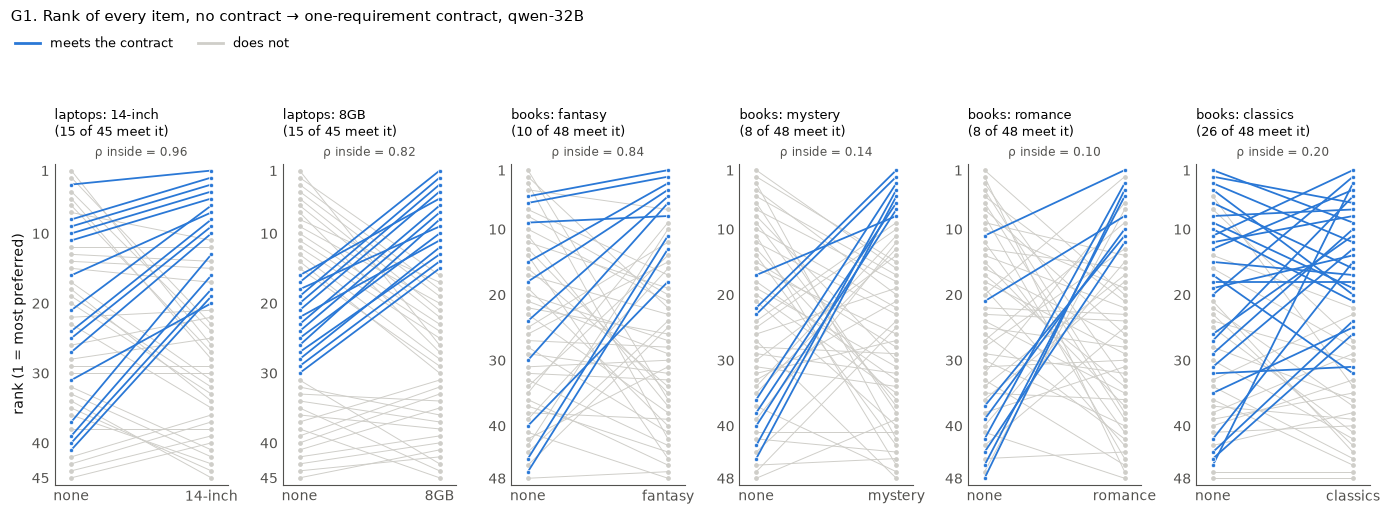

In [3]:
def path_panel(ax, m, dom, cid, ms=3, lw=(0.7, 1.3), title=True):
    r0, r1 = RUN[(dom, m, "none")], RUN[(dom, m, cid)]
    k0, k1 = r0["borda"].rank(ascending=False), r1["borda"].rank(ascending=False)
    s = pd.Series(satisfies(r0, cid), index=r0["items"])
    for it in s.index[~s.values]:
        ax.plot([0, 1], [k0[it], k1[it]], color=LGRAY, lw=lw[0], marker="o", ms=ms * 0.8, zorder=1)
    for it in s.index[s.values]:
        ax.plot([0, 1], [k0[it], k1[it]], color=BLUE, lw=lw[1], marker="o", ms=ms, mec="white", mew=0.5, zorder=2)
    rho = spearmanr(r0["borda"][s.values], r1["borda"][s.values])[0]
    n = len(s)
    ax.set_ylim(n + 1, 0); ax.set_xlim(-0.12, 1.12)
    ax.set_yticks([1, 10, 20, 30, 40, n] if n > 45 else [1, 10, 20, 30, 40, 45])
    ax.set_xticks([0, 1], ["none", CLAB[cid]]); ax.tick_params(length=0)
    ax.text(0.5, -0.015 * n, f"ρ inside = {rho:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK2)
    if title:
        ax.set_title(f"{dom}: {CLAB[cid]}\n({s.sum()} of {n} meet it)", loc="left", fontsize=9.5, pad=20)
    return rho

M1 = "qwen-32B"
fig, axes = plt.subplots(1, 6, figsize=(14, 5.2))
for ax, (dom, cid) in zip(axes, PANELS):
    path_panel(ax, M1, dom, cid)
axes[0].set_ylabel("rank (1 = most preferred)")
fig.legend(handles=[plt.Line2D([], [], color=BLUE, lw=2, label="meets the contract"),
                    plt.Line2D([], [], color=LGRAY, lw=2, label="does not")],
           loc="upper left", bbox_to_anchor=(0.005, 0.95), frameon=False, ncol=2, fontsize=9)
fig.suptitle(f"G1. Rank of every item, no contract → one-requirement contract, {M1}", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.88)); fig.savefig(f"{FIG}/G1_paths_{M1}.png", dpi=150); plt.show()

- **Laptops: the laptops that meet the contract move up as a block, and keep their order.** qwen-32B: ρ inside 0.96
  (`14-inch`) and 0.82 (`8GB`). The model fills the contract with its own taste: among 14-inch laptops it still
  wants the 16GB Apple.
- **Books: the blue lines cross.** ρ inside 0.84 under `fantasy`, but 0.14 (`mystery`), 0.10 (`romance`), 0.20
  (`classics`). The contract picks a new order.
- **The gray lines tell the same story.** Laptops that miss the contract keep their order too (ρ outside 0.75 /
  0.84). Books that miss it do not (0.13 / 0.10 / −0.10 / 0.44).

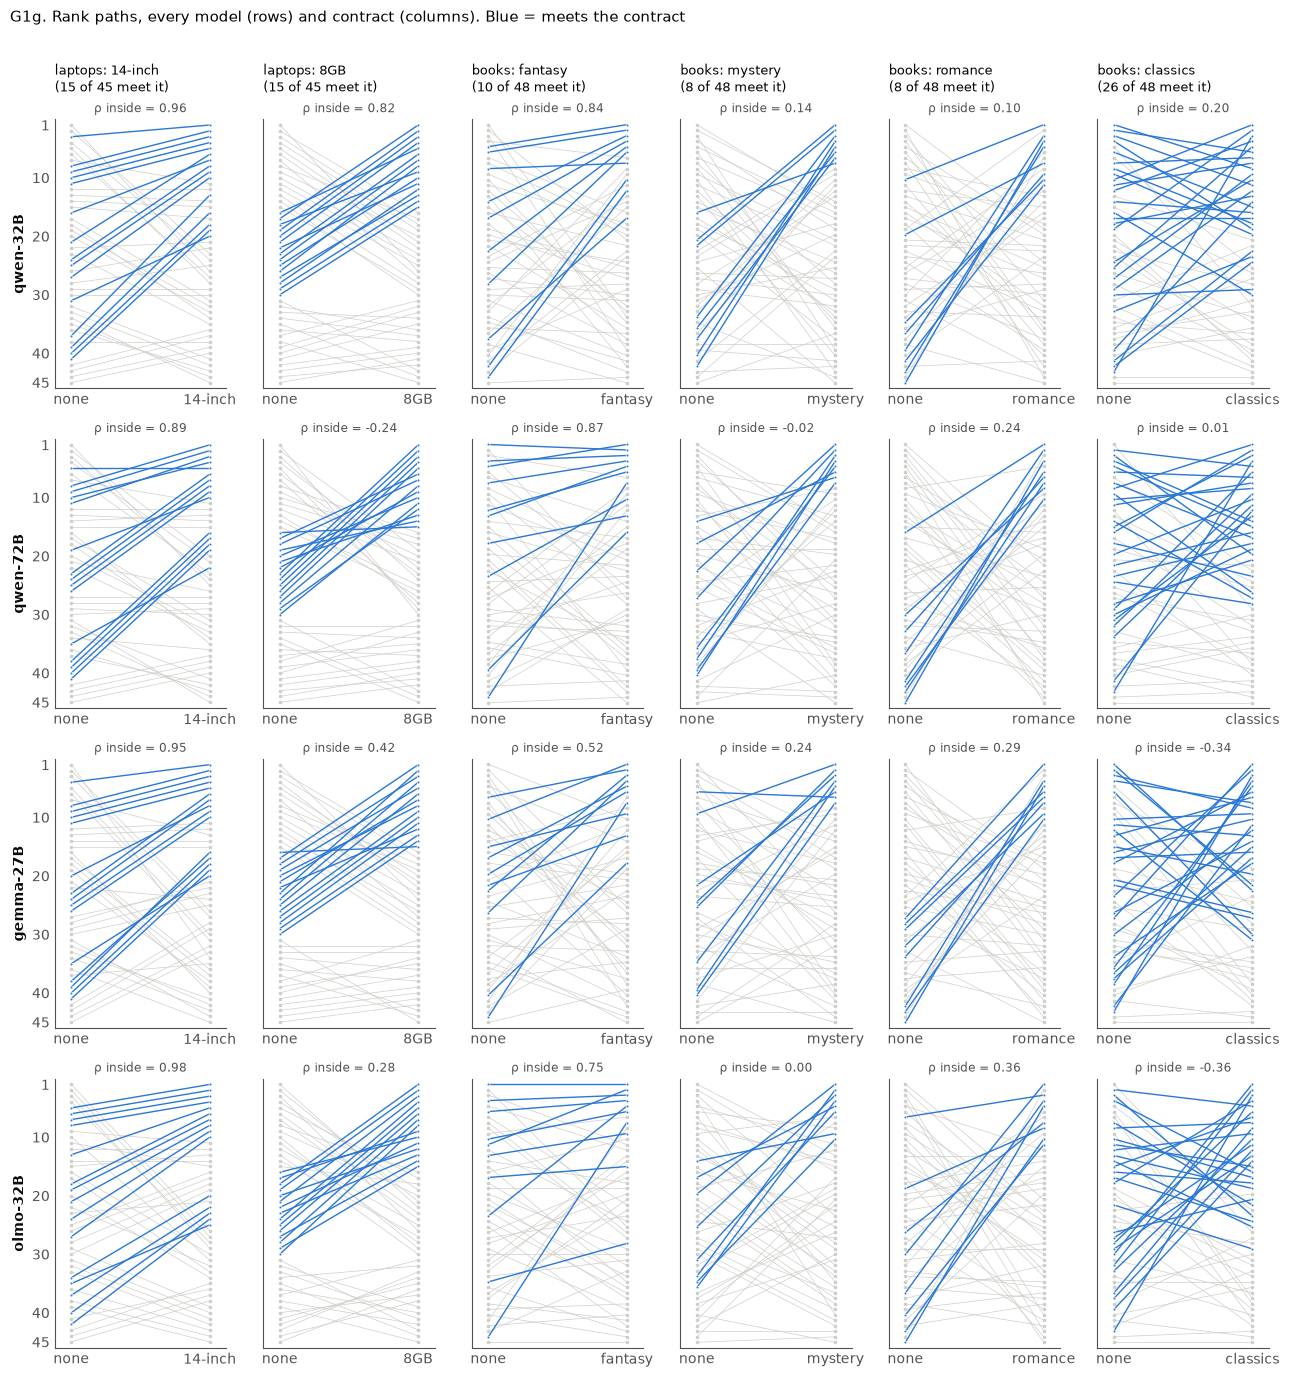

                 laptops               books                                              
          screen=14-inch ram=8GB fantasy=yes mystery-thriller=yes romance=yes classics=yes
gemma-27B           0.95    0.42        0.52                 0.24        0.29        -0.34
olmo-32B            0.98    0.28        0.75                 0.00        0.36        -0.36
qwen-32B            0.96    0.82        0.84                 0.14        0.10         0.20
qwen-72B            0.89   -0.24        0.87                -0.02        0.24         0.01


In [4]:
# G1g: the same, all 4 models (rows) x 6 contracts (columns)
fig, axes = plt.subplots(4, 6, figsize=(13, 14), sharey=False)
RHO_IN = {}
for i, m in enumerate(MODELS):
    for j, (dom, cid) in enumerate(PANELS):
        ax = axes[i, j]
        RHO_IN[(m, dom, cid)] = path_panel(ax, m, dom, cid, ms=2, lw=(0.5, 1.0), title=(i == 0))
        if j == 0: ax.set_ylabel(m, fontsize=10, fontweight="bold")
        if j > 0: ax.set_yticklabels([])
fig.suptitle("G1g. Rank paths, every model (rows) and contract (columns). Blue = meets the contract", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.975)); fig.savefig(f"{FIG}/G1g_paths_all.png", dpi=130); plt.show()
print(pd.Series(RHO_IN).unstack([1, 2]).round(2).to_string())

- **Same picture in all 4 models.** Laptops `14-inch`: ρ inside 0.89–0.98. Books: only `fantasy` keeps the order
  (0.52–0.87); `mystery` −0.02 … 0.24, `romance` 0.10 … 0.36, `classics` −0.36 … 0.20.
- **The one laptop exception is `8GB`** (ρ inside −0.24 … 0.82; qwen-32B 0.82). Inside the 8GB laptops the default
  order is decided by the *small* features: 16-inch first, Apple first. Under `8GB` both go: the 16-inch edge
  disappears (qwen-72B: screen weights +2.1 → −0.1) and Apple falls (+1.9 → −1.7, the known Apple decay). These
  laptops also end up close together (qwen-72B: 10.5–14.9), so small moves reorder them. The RAM ladder itself is
  untouched.

## G2 — feature weights, with the spread over the 5 templates (laptop F5 / F5g)

No contract. `FeatureBT` fitted on each template separately; bar = mean of the 5 fits, error bar = min–max.
As in figs4nir, each template is first rescaled to the mean spread (templates differ mostly in loudness).
- **Laptops**: 11 levels, centred per feature (0 = the average level).
- **Books**: one bar per tag = weight(yes) − weight(no).

**Fit R²** (in the panel) = how much of the raw margins the feature model explains, all templates together.

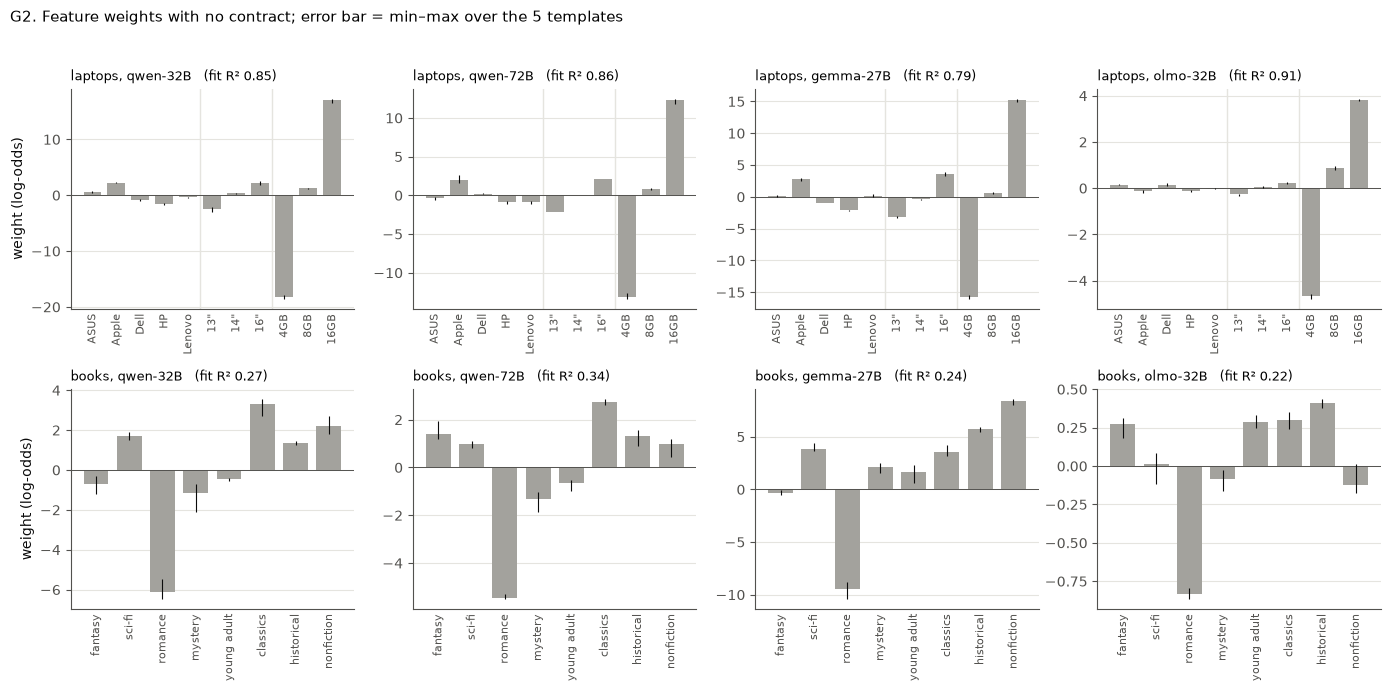

{('laptops', 'qwen-32B'): np.float64(0.853), ('laptops', 'qwen-72B'): np.float64(0.857), ('laptops', 'gemma-27B'): np.float64(0.794), ('laptops', 'olmo-32B'): np.float64(0.907), ('books', 'qwen-32B'): np.float64(0.27), ('books', 'qwen-72B'): np.float64(0.34), ('books', 'gemma-27B'): np.float64(0.237), ('books', 'olmo-32B'): np.float64(0.221)}


In [5]:
TAGS_SHORT = {"fantasy": "fantasy", "science-fiction": "sci-fi", "romance": "romance", "mystery-thriller": "mystery",
              "young-adult": "young adult", "classics": "classics", "historical-fiction": "historical", "nonfiction": "nonfiction"}
def per_template_weights(dom, m):
    d = RUN[(dom, m, "none")]["d"]
    cols = ["score_a", "score_b"] + [f"a_{f}" for f in FEATS[dom]] + [f"b_{f}" for f in FEATS[dom]]
    fits = {t: FeatureBT(r2_warn=None).fit(g[cols]) for t, g in d.groupby("template_idx")}
    S = pd.Series({t: f.total_spread() for t, f in fits.items()}); k = S.mean() / S
    if dom == "laptops":
        lv = [(f, l) for f, ls in [("brand", ["ASUS", "Apple", "Dell", "HP", "Lenovo"]),
                                   ("screen", ["13-inch", "14-inch", "16-inch"]), ("ram", ["4GB", "8GB", "16GB"])] for l in ls]
        W = pd.DataFrame({t: {l.replace("-inch", '"'): fits[t].weights_[f][l] * k[t] for f, l in lv} for t in fits})
    else:
        W = pd.DataFrame({t: {TAGS_SHORT[f]: (fits[t].weights_[f]["yes"] - fits[t].weights_[f]["no"]) * k[t] for f in FEATS[dom]} for t in fits})
    return W

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, dom in enumerate(DOMS):
    for j, m in enumerate(MODELS):
        ax = axes[i, j]; W = per_template_weights(dom, m); mu = W.mean(axis=1); x = np.arange(len(W))
        ax.bar(x, mu, 0.75, color=GRAY, zorder=2)
        ax.errorbar(x, mu, yerr=np.vstack([mu - W.min(axis=1), W.max(axis=1) - mu]), fmt="none", ecolor=INK, elinewidth=0.8, zorder=3)
        ax.axhline(0, color=INK2, lw=0.7)
        ax.set_xticks(x, W.index, rotation=90, fontsize=8); ax.tick_params(axis="x", length=0)
        if dom == "laptops":
            for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1, zorder=0)
        ax.set_title(f"{dom}, {m}   (fit R² {RUN[(dom, m, 'none')]['fbt'].r2_:.2f})", loc="left", fontsize=9.5)
        ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    axes[i, 0].set_ylabel("weight (log-odds)")
fig.suptitle("G2. Feature weights with no contract; error bar = min–max over the 5 templates", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(f"{FIG}/G2_weights.png", dpi=150); plt.show()
print({(dom, m): round(RUN[(dom, m, "none")]["fbt"].r2_, 3) for dom in DOMS for m in MODELS})

- **Laptops: one feature decides — RAM.** RAM range (16GB − 4GB) 35.2 / 25.4 / 30.9 / 8.5 log-odds (qwen-32B,
  qwen-72B, gemma-27B, olmo-32B); brand 0.3–4.8, screen 0.5–6.8.
- **Books: no single tag decides.** The biggest tag is romance, negative in all 4 models (−0.8 to −9.4). Everything
  else is within ±8.4.
- **The features explain the laptops, not the books**: fit R² 0.79–0.91 vs 0.22–0.34.
- **Both domains are stable across templates.** The min–max bars are small next to the weights in every model.

## G3 — theoretical vs empirical utility (laptop F7 / F8)

- **x, theoretical**: the additive feature fit, item = sum of its feature weights.
- **y, empirical**: one free utility per item (here = the Borda score × (n−1)/n, which is exactly the per-item
  OLS fit on this balanced design).

On the diagonal = the features explain that item. **R²** = share of the items' utility the features explain. The 2
items furthest from the diagonal are labelled. No contract.

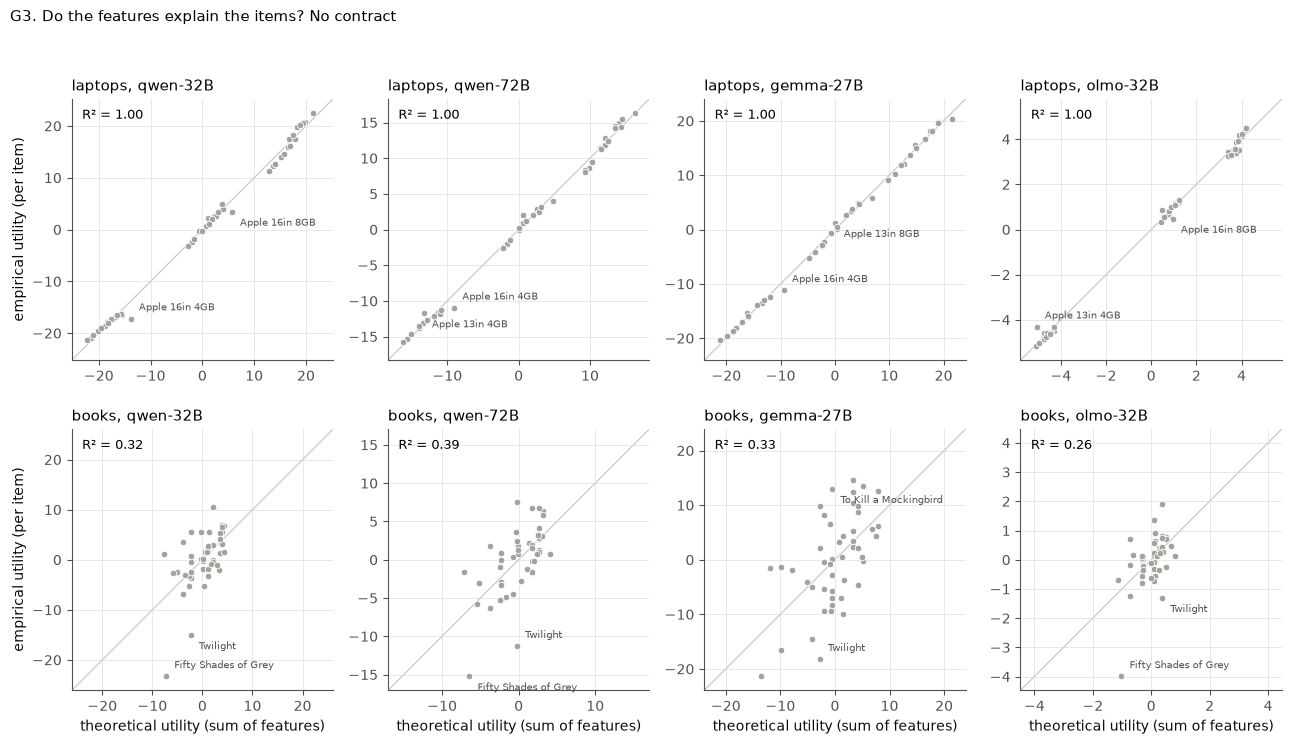

         qwen-32B  qwen-72B  gemma-27B  olmo-32B
laptops      1.00      1.00       0.99      1.00
books        0.76      0.77       0.72      0.78
                min   max
dom     con              
books   False  0.26  0.39
        True   0.60  0.92
laptops False  1.00  1.00
        True   0.97  1.00


In [6]:
SHORTT = {"Harry Potter and the Sorcerer's Stone": "Harry Potter", "The Hitchhiker's Guide to the Galaxy": "Hitchhiker's Guide",
          "The Curious Incident of the Dog in the Night-Time": "Curious Incident", "The Lion, the Witch, and the Wardrobe": "The Lion, the Witch..."}
def tv_panel(ax, r, nlab=2):
    th, em = r["th"], r["em"]
    lim = max(th.abs().max(), em.abs().max()) * 1.12
    ax.plot([-lim, lim], [-lim, lim], color=LGRAY, lw=1, zorder=1)
    ax.scatter(th, em, s=22, color=GRAY, edgecolor="white", linewidth=0.6, zorder=2)
    for k, it in enumerate((em - th).abs().sort_values(ascending=False).index[:nlab]):
        ax.annotate(SHORTT.get(it, it), (th[it], em[it]), xytext=(6, -10 if k else 6), textcoords="offset points", fontsize=7.5, color=INK2)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.text(0.04, 0.96, f"R² = {r['r2u']:.2f}", transform=ax.transAxes, va="top", fontsize=9)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)

fig, axes = plt.subplots(2, 4, figsize=(13, 7.6))
for i, dom in enumerate(DOMS):
    for j, m in enumerate(MODELS):
        tv_panel(axes[i, j], RUN[(dom, m, "none")]); axes[i, j].set_title(f"{dom}, {m}", loc="left")
    axes[i, 0].set_ylabel("empirical utility (per item)")
for ax in axes[1]: ax.set_xlabel("theoretical utility (sum of features)")
fig.suptitle("G3. Do the features explain the items? No contract", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(f"{FIG}/G3_theory_vs_empirical.png", dpi=150); plt.show()
print(pd.DataFrame({dom: {m: RUN[(dom, m, c)]["r2u"] for m in MODELS for c in CONS[dom]} for dom in DOMS}).round(2).T.to_string())
R2C = pd.DataFrame([(dom, m, c, RUN[(dom, m, c)]["r2u"]) for (dom, m, c) in RUN], columns=["dom", "m", "c", "r2"])
print(R2C.assign(con=R2C.c != "none").groupby(["dom", "con"]).r2.agg(["min", "max"]).round(2))

- **Laptops: every point on the diagonal**, R² 1.00 in all 4 models (0.97–1.00 under the contracts). The
  utility of a laptop = the sum of its features. The largest gaps are Apple laptops, and they are small.
- **Books: a cloud**, R² 0.26–0.39. The book itself matters more than its genre. The biggest misses are the same in
  every model: **Fifty Shades of Grey and Twilight sit far below** what their tags predict; To Kill a Mockingbird far
  above (gemma).
- **A contract makes the books more "by genre"**: R² rises to 0.60–0.92 under a contract. Once the user names a
  genre, the model thinks in genres.

## G4 — the two domains on the same axes (laptop F12 + figs4nir2 C)

No contract. One line per model, from laptops to books.
- **template agreement**: mean Spearman between the 5 templates' rankings.
- **sharpness**: mean of tanh(|D|/2) over item pairs; 0 = indifferent, 1 = always sure (position-free).
- **typical preference gap**: median |D| between two items, in log-odds.
- **γ, slot bias**: mean margin slot 1 − slot 2, PMI-corrected. Positive = favours option 1.
- **slot decides**: share of (pair, template) where the same slot wins in both orders, so the order of the options,
  not the items, picked the winner.
- **saturated**: share of queries where the winner gets log-prob ≈ its maximum.
- **features explain (R²)**: from G3.
- **models agree**: mean Spearman between the 4 models' rankings — one number per domain (black).

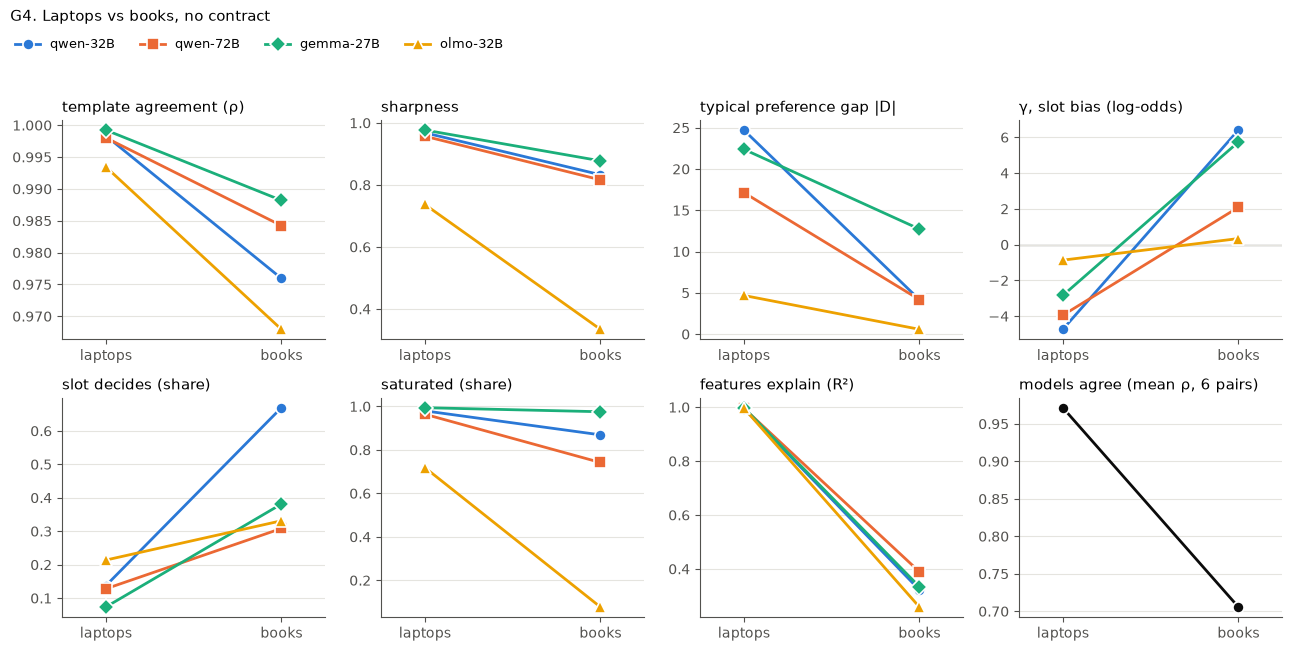

       laptops                                books                            
      qwen-32B qwen-72B gemma-27B olmo-32B qwen-32B qwen-72B gemma-27B olmo-32B
tmpl     0.998    0.998     0.999    0.993    0.976    0.984     0.988    0.968
sharp    0.968    0.957     0.977    0.737    0.833    0.816     0.878    0.334
medD    24.715   17.142    22.385    4.681    4.175    4.180    12.726    0.580
gamma   -4.734   -3.946    -2.841   -0.868    6.403    2.084     5.734    0.338
slot     0.137    0.128     0.074    0.214    0.669    0.308     0.381    0.331
sat      0.979    0.964     0.994    0.719    0.869    0.742     0.975    0.077
r2u      0.996    0.996     0.998    0.997    0.322    0.390     0.334    0.259
models agree: {'laptops': np.float64(0.97), 'books': np.float64(0.71)}


In [7]:
MET = [("tmpl", "template agreement (ρ)"), ("sharp", "sharpness"), ("medD", "typical preference gap |D|"),
       ("gamma", "γ, slot bias (log-odds)"), ("slot", "slot decides (share)"), ("sat", "saturated (share)"),
       ("r2u", "features explain (R²)")]
AGREE = {dom: np.mean([spearmanr(RUN[(dom, a, "none")]["borda"], RUN[(dom, b, "none")]["borda"])[0]
                       for a, b in itertools.combinations(MODELS, 2)]) for dom in DOMS}
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for ax, (k, t) in zip(axes.flat, MET):
    for m in MODELS:
        ax.plot([0, 1], [RUN[(dom, m, "none")][k] for dom in DOMS], color=MC[m], marker=MK[m], lw=2, ms=8, mec="white", mew=1.2, label=m)
    if k == "gamma": ax.axhline(0, color=GRAY, lw=1, zorder=0)
    ax.set_title(t, loc="left")
ax = axes.flat[-1]
ax.plot([0, 1], [AGREE[d] for d in DOMS], color=INK, marker="o", lw=2, ms=8, mec="white", mew=1.2)
ax.set_title("models agree (mean ρ, 6 pairs)", loc="left")
for ax in axes.flat:
    ax.set_xticks([0, 1], DOMS); ax.set_xlim(-0.25, 1.25); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.955), frameon=False, ncol=4, fontsize=9)
fig.suptitle("G4. Laptops vs books, no contract", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.91)); fig.savefig(f"{FIG}/G4_summary.png", dpi=150); plt.show()
SUM = pd.DataFrame({(dom, m): {k: RUN[(dom, m, "none")][k] for k, _ in MET} for dom in DOMS for m in MODELS})
print(SUM.round(3).to_string()); print("models agree:", {d: round(v, 2) for d, v in AGREE.items()})

- **Every measure moves the same way in all 4 models: the book preference is weaker and less stable.**
  - template agreement 0.993–0.999 → 0.968–0.988;
  - sharpness 0.74–0.98 → 0.33–0.88; typical gap |D| 4.7–24.7 → 0.6–12.7 log-odds;
  - saturated 72–99% → 8–98% (olmo-32B falls to 8%).
- **The slot bias flips sign.** Laptops: γ −0.9 … −4.7 (all models favour option 2). Books: +0.3 … +6.4 (favour
  option 1). Same models and templates; only the frame sentence and the items differ.
- **Option order picks the winner far more often in books**: slot decides 7–21% → 31–67%. In qwen-32B books, 67% of
  single queries are decided by the order, because its γ (6.4) is larger than its typical gap (4.2). D removes this
  for the analysis, but a single book query is mostly a coin of the order.
- **The models agree much less on books**: mean ρ between the 4 models 0.97 → 0.71.
- **The features stop explaining**: R² 0.996–0.998 → 0.26–0.39 (G3).

## G5 — the contract in both domains (laptop F11)

For each contract, three questions. **Mixed pair** = one item meets the contract, the other does not.
1. **Obeyed?** Share of mixed pairs the item that meets the contract wins, by the position-corrected D.
   Gray = with no contract, colour = with it.
2. **Order kept inside?** Spearman between the old and the new order of the items that **meet** the contract.
   1 = the model fills the contract with its own taste.
3. **Order kept outside?** The same for the items that do **not** meet it.

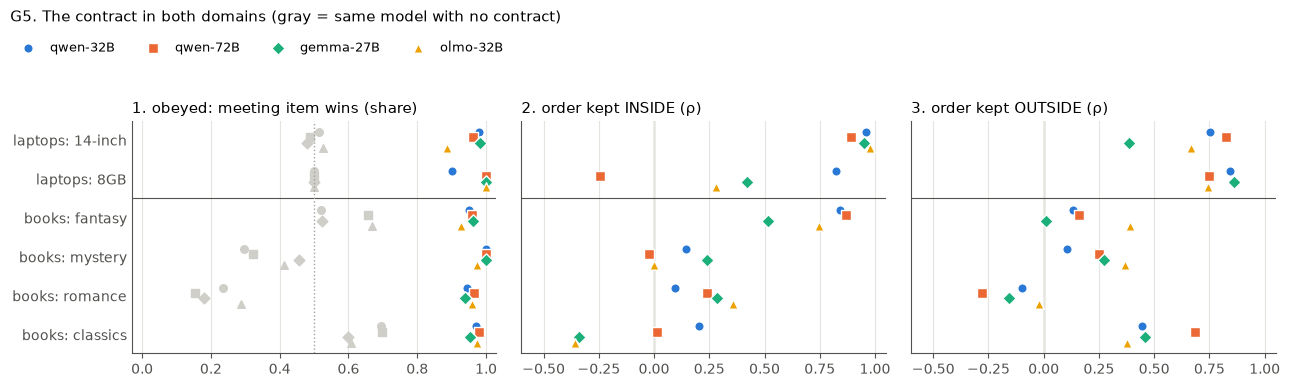

                            win_none  win_con  inside  outside  overall
contract         model                                                 
laptops: 14-inch qwen-32B       0.51     0.98    0.96     0.75     0.51
                 qwen-72B       0.49     0.96    0.89     0.82     0.53
                 gemma-27B      0.48     0.98    0.95     0.39     0.32
                 olmo-32B       0.53     0.89    0.98     0.67     0.54
laptops: 8GB     qwen-32B       0.50     0.90    0.82     0.84     0.50
                 qwen-72B       0.50     1.00   -0.24     0.75     0.43
                 gemma-27B      0.50     1.00    0.42     0.86     0.49
                 olmo-32B       0.50     1.00    0.28     0.75     0.45
books: fantasy   qwen-32B       0.52     0.95    0.84     0.13     0.17
                 qwen-72B       0.66     0.96    0.87     0.16     0.33
                 gemma-27B      0.52     0.96    0.52     0.01     0.07
                 olmo-32B       0.67     0.93    0.75     0.39  

In [8]:
rows = []
for dom, cid in PANELS:
    for m in MODELS:
        r0, r1 = RUN[(dom, m, "none")], RUN[(dom, m, cid)]
        s = satisfies(r0, cid)
        rows.append(dict(contract=f"{dom}: {CLAB[cid]}", model=m,
                         win_none=(r0["D"][np.ix_(s, ~s)] > 0).mean(), win_con=(r1["D"][np.ix_(s, ~s)] > 0).mean(),
                         inside=spearmanr(r0["borda"][s], r1["borda"][s])[0],
                         outside=spearmanr(r0["borda"][~s], r1["borda"][~s])[0],
                         overall=spearmanr(r0["borda"], r1["borda"])[0]))
CT = pd.DataFrame(rows).set_index(["contract", "model"])
ROWS = list(dict.fromkeys(CT.index.get_level_values(0)))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
y0 = np.arange(len(ROWS))[::-1]
for ax, col, t in zip(axes, ["win_con", "inside", "outside"], ["1. obeyed: meeting item wins (share)", "2. order kept INSIDE (ρ)", "3. order kept OUTSIDE (ρ)"]):
    for i, m in enumerate(MODELS):
        yy = y0 + (1.5 - i) * 0.14
        if col == "win_con":
            ax.scatter(CT.xs(m, level="model").loc[ROWS, "win_none"], yy, s=30, color=LGRAY, marker=MK[m], zorder=2)
        ax.scatter(CT.xs(m, level="model").loc[ROWS, col], yy, s=46, color=MC[m], marker=MK[m], edgecolor="white", linewidth=1, zorder=3, label=m)
    ax.axhline(3.5, color=INK2, lw=0.8); ax.set_title(t, loc="left")
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
axes[0].set_yticks(y0, ROWS); axes[0].axvline(0.5, color=GRAY, ls=":", lw=1)
axes[0].set_xlim(-0.03, 1.03); axes[1].set_xlim(-0.6, 1.05); axes[2].set_xlim(-0.6, 1.05)
for ax in axes[1:]: ax.axvline(0, color=GRAY, lw=1, zorder=0)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.93), frameon=False, ncol=4, fontsize=9)
fig.suptitle("G5. The contract in both domains (gray = same model with no contract)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/G5_contract.png", dpi=150); plt.show()
print(CT.round(2).to_string())
print(CT.groupby(lambda k: k[0].split(":")[0]).agg(["min", "max"]).round(2).T.to_string())

- **Obeyed in both domains**: the item that meets the contract wins 89–100% of mixed pairs (laptops), 93–100% (books).
  With no contract it is ~50% for laptops (half the mixed pairs are free wins, half are conflicts) and 15–70% for books.
- **Order inside — the main difference.** Laptops `14-inch` 0.89–0.98 (`8GB` −0.24 … 0.82, see G1g). Books 0.52–0.87
  for `fantasy`, −0.36 … 0.36 for the other three.
- **Order outside.** Laptops 0.39–0.86. Books −0.28 … 0.69, and **negative in all 4 models under `romance`**
  (−0.28 … −0.02): the contract reorders even the books it does not ask for.

## Summary

| | laptops | books |
|---|---|---|
| what the default is about | one feature (RAM): R² ≈ 1.00 | the book itself: R² 0.26–0.39 |
| how strong / stable | sharpness 0.74–0.98, templates 0.99+ | 0.33–0.88, templates 0.97–0.99 |
| do the 4 models agree? | ρ 0.97 | ρ 0.71 |
| slot bias | favours option 2; decides 7–21% | favours option 1; decides 31–67% |
| contract obeyed? | 89–100% | 93–100% |
| old order kept inside the contract? | **yes** (`14-inch` 0.89–0.98) | **no**, except `fantasy` (others −0.36 … 0.36) |

1. **Laptops: the contract is a filter.** The model applies it, then fills the rest with its own taste — the main
   conjecture in its clean form.
2. **Books: the contract replaces the taste.** Obeyed just as well, but inside the genre the model re-ranks by "how
   typical of the genre" (books_48, section 5), and even the books outside the genre get reordered.
3. **So whether a model completes a contract with its own preference depends on the domain.** It does when the
   preference sits on the same features as the contract (laptops), not when it sits on the items (books).
4. **Positional bias is a domain property, not a model property**: the same 4 models favour option 2 on laptops
   and option 1 on books, and the share of answers it decides goes from 7–21% to 31–67%.